# Monte Carlo demo
MonteCarloResult with made-up paths whose statistics can be checked by hand, then `Portfolio.monte_carlo` with made-up prices whose parameters are known, its errors, and finally real data from Yahoo Finance.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / 'src' / 'models'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv

load_dotenv(project_root / '.env')

from asset_fetcher import AssetFetcher
from cryptocurrency import Cryptocurrency
from monte_carlo import MonteCarloResult
from portfolio import Portfolio
from priceseries import PriceSeries
from stock import Stock

## MonteCarloResult: three known paths
Three simulations of 2 steps that end at 110, 95 and 80 from 100. Final returns are +10 %, -5 % and -20 %, so every statistic can be checked by hand.

In [2]:
known = pd.DataFrame([[100, 100, 100], [105, 98, 90], [110, 95, 80]], dtype=float)
result = MonteCarloResult(
    paths=known, target='portfolio', mu=0.0, sigma=0.1, periods_per_year=252, seed=None
)

print("Initial value:", result.initial_value, "(expected 100)")
print("Final returns:", result.final_returns.round(4).tolist(), "(expected [0.1, -0.05, -0.2])")
print("Mean:", round(result.mean(), 4), "(expected -0.05)")
print("Median:", round(result.median(), 4), "(expected -0.05)")
print("Loss probability:", round(result.loss_probability(), 4), "(expected 2/3 = 0.6667)")
print("VaR 95%:", round(result.var(0.95), 4), "(5th percentile -0.185, as a loss)")
print("CVaR 95%:", round(result.cvar(0.95), 4), "(only -0.20 is worse, as a loss)")
result.percentiles()

Initial value: 100.0 (expected 100)
Final returns: [0.1, -0.05, -0.2] (expected [0.1, -0.05, -0.2])
Mean: -0.05 (expected -0.05)
Median: -0.05 (expected -0.05)
Loss probability: 0.6667 (expected 2/3 = 0.6667)
VaR 95%: 0.185 (5th percentile -0.185, as a loss)
CVaR 95%: 0.2 (only -0.20 is worse, as a loss)


5.0    -0.185
25.0   -0.125
50.0   -0.050
75.0    0.025
95.0    0.085
Name: final_return, dtype: float64

In [3]:
result.summary()

{'mean': -0.04999999999999997,
 'median': -0.050000000000000044,
 'var_95': 0.18499999999999994,
 'cvar_95': 0.19999999999999996,
 'var_99': 0.19699999999999995,
 'cvar_99': 0.19999999999999996,
 'loss_probability': 0.6666666666666666}

In [4]:
BASE = {'paths': known, 'target': 'portfolio', 'mu': 0.0, 'sigma': 0.1,
        'periods_per_year': 252, 'seed': None}

bad_results = {
    'paths_not_dataframe': {'paths': known.to_numpy()},
    'one_row': {'paths': known.iloc[:1]},
    'negative_value': {'paths': known.replace(80.0, -1.0)},
    'negative_sigma': {'sigma': -1.0},
    'zero_periods': {'periods_per_year': 0},
}
for label, override in bad_results.items():
    try:
        MonteCarloResult(**{**BASE, **override})
        print(f"{label}: NO ERROR (wrong)")
    except (TypeError, ValueError) as e:
        print(f"{label}: {type(e).__name__}: {e}")

bad_calls = {
    'level_above_one': lambda: result.var(1.5),
    'level_bool': lambda: result.var(True),
    'percentile_above_100': lambda: result.percentiles(q=(150,)),
}
for label, call in bad_calls.items():
    try:
        call()
        print(f"{label}: NO ERROR (wrong)")
    except (TypeError, ValueError) as e:
        print(f"{label}: {type(e).__name__}: {e}")

paths_not_dataframe: TypeError: paths must be a DataFrame, got ndarray
one_row: ValueError: paths must have at least 2 steps and 1 simulation, got shape (1, 3)
negative_value: ValueError: paths must contain positive finite values
negative_sigma: ValueError: sigma must be non-negative and finite, got -1.0
zero_periods: ValueError: periods_per_year must be positive, got 0
level_above_one: ValueError: level must be between 0 and 1, got 1.5
level_bool: ValueError: level must be between 0 and 1, got True
percentile_above_100: ValueError: q must be between 0 and 100, got [150.0]


## Portfolio.monte_carlo: made-up prices
Two stocks follow a log-normal walk with known daily `mu` and `sigma` on a daily calendar. The portfolio holds 60 % and 30 %, and the other 10 % stays in cash.

In [5]:
TRUE = {'AAA': (0.0004, 0.010), 'BBB': (0.0002, 0.015)}  # daily mu, sigma of log returns
dates = pd.date_range('2024-01-01', periods=500, freq='D')

def make_stock(ticker, mu, sigma, seed):
    log_returns = np.random.default_rng(seed).normal(mu, sigma, len(dates))
    close = pd.Series(100 * np.exp(np.cumsum(log_returns)), index=dates)
    prices = PriceSeries(date=dates, open=close, high=close, low=close, close=close, volume=None)
    return Stock(ticker=ticker, price=prices, company=None)

aaa = make_stock('AAA', *TRUE['AAA'], seed=1)
bbb = make_stock('BBB', *TRUE['BBB'], seed=2)
synthetic = Portfolio.from_weights([aaa, bbb], {'AAA': 0.6, 'BBB': 0.3}, 10_000, dates[0])
synthetic.weights().round(4)

AAA    0.6551
BBB    0.2376
Name: 2025-05-14 00:00:00, dtype: float64

In [6]:
mc = synthetic.monte_carlo(5_000, 1.0, seed=42)
steps = len(mc.paths) - 1

print(mc.paths.shape, "-> steps + 1 rows, one column per simulation")
print("Steps per year:", mc.periods_per_year, "| steps:", steps)
print("Row 0:", round(mc.initial_value, 2), "| portfolio value today:",
      round(float(synthetic.value().dropna().iloc[-1]), 2))
print("Same seed, same paths:", mc.paths.equals(synthetic.monte_carlo(5_000, 1.0, seed=42).paths))
print("Other seed, other paths:", not mc.paths.equals(synthetic.monte_carlo(5_000, 1.0, seed=7).paths))

(366, 5000) -> steps + 1 rows, one column per simulation
Steps per year: 365.0 | steps: 365
Row 0: 9319.94 | portfolio value today: 9319.94
Same seed, same paths: True
Other seed, other paths: True


One asset only: the simulation starts at its last price, and `mu` and `sigma` are estimated from its history. `sigma` comes out close to the true value, but `mu` does not: with 500 days its standard error, sigma / sqrt(n), is larger than `mu` itself. Estimating the drift needs far more history than estimating the volatility, and Monte Carlo inherits that uncertainty.

In [7]:
mc_aaa = synthetic.monte_carlo(5_000, 1.0, asset='AAA', seed=42)

print("Target:", mc_aaa.target)
print("Row 0:", round(mc_aaa.initial_value, 4), "| last AAA price:", round(float(aaa.price.close.iloc[-1]), 4))
n = len(aaa.price.close) - 1
parameters = pd.DataFrame({
    'true': TRUE['AAA'],
    'estimated': (mc_aaa.mu, mc_aaa.sigma),
    'standard error': (mc_aaa.sigma / np.sqrt(n), mc_aaa.sigma / np.sqrt(2 * n)),
}, index=['mu', 'sigma'])
parameters.round(5)

Target: AAA
Row 0: 102.1537 | last AAA price: 102.1537


,true,estimated,standard error
mu,0.0004,0.00003,0.00041
sigma,0.0100,0.00915,0.00029


The simulated log returns must have the `mu` and `sigma` they were drawn with, and the mean final log return must be about `steps * mu`.

In [8]:
simulated = np.log(mc.paths).diff().iloc[1:]
final_log = np.log(mc.paths.iloc[-1] / mc.paths.iloc[0])

moments = pd.DataFrame({
    'expected': [mc.mu, mc.sigma, steps * mc.mu],
    'simulated': [simulated.stack().mean(), simulated.stack().std(), final_log.mean()],
}, index=['mu per step', 'sigma per step', 'mean final log return'])
moments

,expected,simulated
mu per step,-0.000091,-0.000087
sigma per step,0.007005,0.007006
mean final log return,-0.033334,-0.031607


### Errors
Invalid arguments, a portfolio without assets and a trade after the last common price date are rejected. Stock prices are carried forward to any later date, so only crypto, which is never filled, can leave a trade after the last common date: here its prices stop 30 days before the stock trade.

In [9]:
crypto_prices = aaa.price.close.iloc[:-30]
ccc = Cryptocurrency(
    name='Made-up coin', symbol='CCC', blockchain=[], market_cap=None, market_cap_rank=None,
    tokenomics=None,
    price=PriceSeries(date=crypto_prices.index, open=crypto_prices, high=crypto_prices,
                      low=crypto_prices, close=crypto_prices, volume=None),
)
after_last_price = Portfolio.from_weights([aaa, ccc], {'AAA': 0.5, 'CCC': 0.5}, 10_000, dates[0])
after_last_price.buy(aaa, 1, dates[-1])

bad_simulations = {
    'zero_simulations': lambda: synthetic.monte_carlo(0),
    'bool_simulations': lambda: synthetic.monte_carlo(True),
    'float_simulations': lambda: synthetic.monte_carlo(2.5),
    'negative_years': lambda: synthetic.monte_carlo(years=-1),
    'zero_years': lambda: synthetic.monte_carlo(years=0),
    'text_years': lambda: synthetic.monte_carlo(years='one'),
    'nan_years': lambda: synthetic.monte_carlo(years=float('nan')),
    'less_than_one_step': lambda: synthetic.monte_carlo(years=0.0001),
    'unknown_asset': lambda: synthetic.monte_carlo(asset='XXX'),
    'no_assets': lambda: Portfolio(10_000, '2024-01-01').monte_carlo(),
    'trade_after_last_price': lambda: after_last_price.monte_carlo(),
}
for label, call in bad_simulations.items():
    try:
        call()
        print(f"{label}: NO ERROR (wrong)")
    except (TypeError, ValueError) as e:
        print(f"{label}: {type(e).__name__}: {e}")

zero_simulations: ValueError: n_simulations must be a positive integer, got 0
bool_simulations: ValueError: n_simulations must be a positive integer, got True
float_simulations: ValueError: n_simulations must be a positive integer, got 2.5
negative_years: ValueError: years must be positive and finite, got -1
zero_years: ValueError: years must be positive and finite, got 0
text_years: ValueError: years must be positive and finite, got 'one'
nan_years: ValueError: years must be positive and finite, got nan
less_than_one_step: ValueError: years must cover at least one step, got 0.0001 with 365.0 steps per year
unknown_asset: ValueError: asset must be one of ['AAA', 'BBB'], got 'XXX'
no_assets: ValueError: Portfolio has no assets to simulate
trade_after_last_price: ValueError: Simulation needs a common valuation after the last movement


## Real data: Yahoo Finance
AAPL, MSFT and the S&P 500 over the last two years. No API key needed. Crypto is left out on purpose: with more than 30 days of history CoinGecko returns one price every 4 days, and aligning that with daily stocks is still pending.

In [10]:
today = pd.Timestamp.today().normalize()
fetcher = AssetFetcher()
assets = fetcher.get_many(
    [{'type': 'stock', 'api': 'yfinance', 'symbol': 'AAPL'},
     {'type': 'stock', 'api': 'yfinance', 'symbol': 'MSFT'},
     {'type': 'index', 'api': 'yfinance', 'symbol': '^GSPC'}],
    start=today - pd.DateOffset(years=2), end=today,
)
reports = pd.DataFrame({symbol: vars(report) for symbol, report in fetcher.cleaning_reports.items()})
reports

,AAPL,MSFT,^GSPC
n_input,500,500,500
n_output,500,500,500
invalid_dates,0,0,0
duplicates,0,0,0
missing,0,0,0
timezone,America/New_York,America/New_York,America/New_York


In [11]:
start = max(asset.price.close.index[0] for asset in assets)
real = Portfolio.from_weights(assets, {'AAPL': 0.4, 'MSFT': 0.3, '^GSPC': 0.3}, 10_000, start)

mc_real = real.monte_carlo(10_000, 1.0, seed=42)
summaries = {'portfolio': mc_real.summary()}
for symbol in real.assets:
    summaries[symbol] = real.monte_carlo(10_000, 1.0, asset=symbol, seed=42).summary()

print("One-year horizon, in %:")
(pd.DataFrame(summaries) * 100).round(2)

One-year horizon, in %:


,portfolio,AAPL,MSFT,^GSPC
mean,21.39,29.19,18.44,12.74
median,18.63,23.64,13.26,11.11
var_95,15.30,22.73,29.52,14.83
cvar_95,22.04,31.07,37.20,20.27
var_99,26.09,36.11,41.83,23.52
cvar_99,31.32,42.26,47.48,27.86
loss_probability,20.45,23.33,33.66,26.23


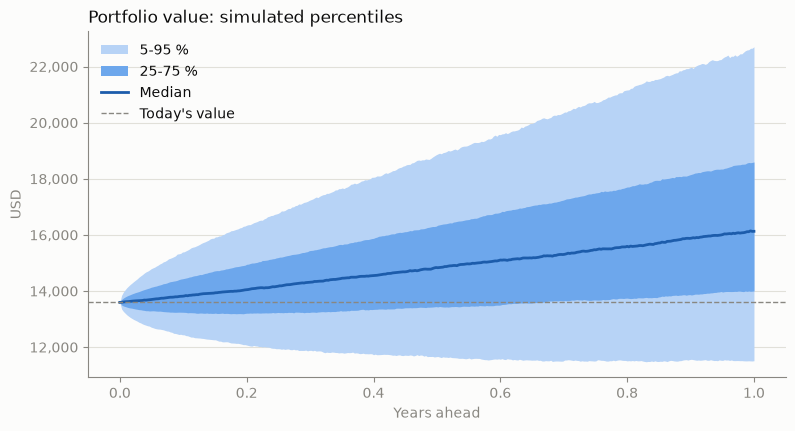

In [12]:
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9'
BAND_OUTER, BAND_INNER, MEDIAN = '#b7d3f6', '#6da7ec', '#1c5cab'

def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis='y', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

bands = mc_real.paths.quantile([0.05, 0.25, 0.5, 0.75, 0.95], axis=1).T
horizon = mc_real.paths.index / mc_real.periods_per_year

fig, ax = plt.subplots(figsize=(9, 4.5), facecolor=SURFACE)
style(ax)
ax.fill_between(horizon, bands[0.05], bands[0.95], color=BAND_OUTER, linewidth=0, label="5-95 %")
ax.fill_between(horizon, bands[0.25], bands[0.75], color=BAND_INNER, linewidth=0, label="25-75 %")
ax.plot(horizon, bands[0.5], color=MEDIAN, linewidth=2, label="Median")
ax.axhline(mc_real.initial_value, color=MUTED, linewidth=1, linestyle='--', label="Today's value")
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_title("Portfolio value: simulated percentiles", loc='left', color=INK)
ax.set_xlabel("Years ahead", color=MUTED)
ax.set_ylabel("USD", color=MUTED)
ax.legend(frameon=False, loc='upper left', labelcolor=INK)
plt.show()

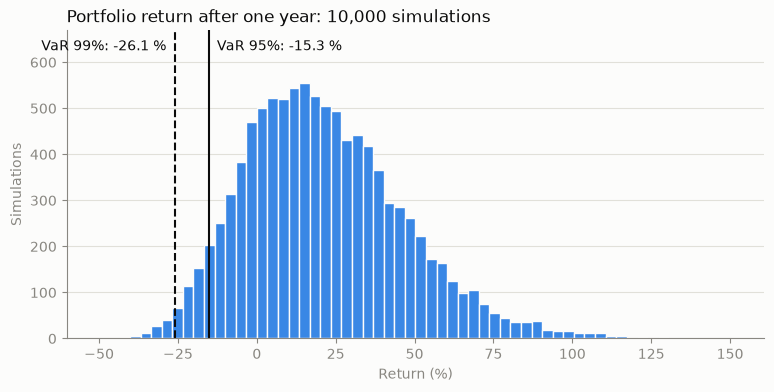

In [13]:
returns = mc_real.final_returns * 100

fig, ax = plt.subplots(figsize=(9, 4), facecolor=SURFACE)
style(ax)
ax.hist(returns, bins=60, color='#3987e5', edgecolor=SURFACE, linewidth=1)
top = ax.get_ylim()[1] * 1.15  # headroom so the labels clear the bars
ax.set_ylim(top=top)
for level, dash, side, offset in ((0.95, '-', 'left', 6), (0.99, '--', 'right', -6)):
    loss = -mc_real.var(level) * 100
    ax.axvline(loss, color=INK, linewidth=1.5, linestyle=dash)
    ax.annotate(f"VaR {level:.0%}: {loss:.1f} %", (loss, top * 0.97), xytext=(offset, 0),
                textcoords='offset points', ha=side, va='top', color=INK)
ax.set_title("Portfolio return after one year: 10,000 simulations", loc='left', color=INK)
ax.set_xlabel("Return (%)", color=MUTED)
ax.set_ylabel("Simulations", color=MUTED)
plt.show()

`periods_per_year` comes out as 365 instead of about 252: `Portfolio._closes()` fills weekends with the last close, so weekends add zero returns. `sigma` per step is lower, but there are more steps, so the one-year horizon stays consistent.

## Shorts and leverage
Short the S&P 500 and borrow cash to buy more stocks: at purchase, net exposure 120 % and cash -20 %. Weights drift with prices, and the simulation uses today's weights. Cash earns 0, so the borrowing adds risk but no cost.

In [14]:
leveraged = Portfolio.from_weights(assets, {'AAPL': 0.9, 'MSFT': 0.6, '^GSPC': -0.3}, 10_000, start)
print("Cash weight today:", round(leveraged.cash_weight(), 4), "(-0.20 at purchase)")

comparison = pd.DataFrame({
    'long only': mc_real.summary(),
    'long-short': leveraged.monte_carlo(10_000, 1.0, seed=42).summary(),
})
(comparison * 100).round(2)

Cash weight today: -0.1279 (-0.20 at purchase)


,long only,long-short
mean,21.39,31.98
median,18.63,25.86
var_95,15.30,22.83
cvar_95,22.04,31.46
var_99,26.09,36.68
cvar_99,31.32,43.00
loss_probability,20.45,22.34
